In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, MultiLabelBinarizer, OrdinalEncoder
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import make_pipeline, Pipeline
import seaborn as sns
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import winsound


RANDOM_STATE = 22
CV = 5

In [2]:
df = pd.read_csv("../../Datasets/Processed/Dataset Dupilumab Baseline.xlsx - Anagrafica.csv")
df.shape

(112, 48)

In [3]:
# df.head()

In [4]:
# df.info()

In [5]:
# df.columns

In [6]:
y = df['TARGET']
mesi = df['Mesi senza Eosinophilia']
df.drop(columns=['TARGET', 'Mesi senza Eosinophilia'], inplace=True)
df.shape, y.shape

C:\Users\lucac\AppData\Local\Temp\ipykernel_17580\629778941.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['TARGET', 'Mesi senza Eosinophilia'], inplace=True)


((112, 46), (112,))

In [7]:
all_features = {
    "num_cont": [
        "Peso (kg)",
        "Altezza (cm)",
        "Fumo Score",
        "Neutrofili",
        "Linfociti",
        "Monociti",
        "Eosinofili",
        "Basofili",
        "IgE totali",
    ],
    "num_discr": [
        "Età",
        "Num Comorbidità",
        "Anni di astinenza",
        "Siga al giorno",
        "Numero di pregressi interventi ESS",
        "N. allergeni positivi",
        "Giorni al mese di utilizzo spray",
        "ACT",
        "NPS",
        "Physical Symptoms",
        "Health and QoL",
        "Nasal Symptoms",
        "Otologic Symptoms",
        "Sleep Symptoms",
        "Emotional Symptoms",
        "NCS",
        "Ostruzione nasale",
        "Rinorrea anteriore",
        "Rinorrea posteriore",
        "Dolore facciale",
        "Starnuti",
        "QoL",
    ],
    "cat": [
        "Categoria Professione",
        "Sesso",
        "Biologico precedente (0 no, 1 sì)",
        "Familiarità Atopia",
        "OCS nell'ultimo anno",
        "Intolleranza ai FANS",
    ],
    "multi_cat": [
        "Comorbidità",
        "Quali allergeni positivi",
        "Categorie Allergeni",
    ],
    "ord": [
        "Cellule caliciformi mucipare",
        "Citologico_Neutrofili",
        "Citologico_Eosinofili",
        "Fumo Baseline (0=no, 1=ex, 2=si)",
    ],
}

In [8]:
continuous_cols = [
    "Peso (kg)",
    "Altezza (cm)",
    "Neutrofili",
    "Linfociti",
    "Monociti",
    "Eosinofili",
    "Basofili",
    "IgE totali",
]

discrete_cols = [
    "Età",
    "Num Comorbidità",
    "Numero di pregressi interventi ESS",
    "N. allergeni positivi",
    "Giorni al mese di utilizzo spray",
    "ACT",
    "NPS",
    "Physical Symptoms",
    # "Health and QoL",
    # "Nasal Symptoms",
    # "Otologic Symptoms",
    "Sleep Symptoms",
    "Emotional Symptoms",
    # "NCS",
    "Ostruzione nasale",
    "Rinorrea anteriore",
    "Rinorrea posteriore",
    # "Dolore facciale",
    "Starnuti",
    "QoL",
]

categorical_cols = all_features["cat"].copy()

multi_categorical_cols = [
    "Comorbidità",
    "Quali allergeni positivi",
]

ordinal_cols = [
    "Fumo Baseline (0=no, 1=ex, 2=si)",
]

df[continuous_cols] = df[continuous_cols].apply(
    lambda col: col.astype("string")
                   .str.replace(".", "", regex=False)
                   .str.replace(",", ".", regex=False)
                   .astype("float64")
)
df[discrete_cols] = df[discrete_cols].astype("float64")
df[ordinal_cols] = df[ordinal_cols].astype("float64")

In [9]:
# # PLOT CORRELAZIONI VAS SNOT
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# features = [
#     "ACT",
#     "NPS",
#     "Physical Symptoms",
#     "Health and QoL",
#     "Nasal Symptoms",
#     "Otologic Symptoms",
#     "Sleep Symptoms",
#     "Emotional Symptoms",
#     "NCS",
#     "Ostruzione nasale",
#     "Rinorrea anteriore",
#     "Rinorrea posteriore",
#     "Dolore facciale",
#     "Starnuti",
#     "QoL",
# ]

# missing = [col for col in features if col not in df.columns]
# if missing:
#     print("Colonne non trovate:", missing)

# available = [col for col in features if col in df.columns]
# if not available:
#     raise ValueError("Nessuna delle feature richieste è presente in df.")

# values = df[available].apply(pd.to_numeric, errors="coerce")
# target = pd.to_numeric(pd.Series(y, index=df.index), errors="coerce")

# correlations = values.corrwith(target, method="spearman").sort_values()

# plt.figure(figsize=(9, 5))
# sns.barplot(x=correlations.values, y=correlations.index, color="steelblue")
# plt.axvline(0, color="black", linewidth=0.8)
# plt.xlabel("Correlazione di Spearman con il target")
# plt.ylabel("")
# plt.title("Correlazione tra target e sintomi")
# plt.tight_layout()
# plt.show()

# display(correlations.rename("correlazione_spearman").to_frame())

# feature_correlations = values.corr(method="spearman")
# feature_correlations = feature_correlations.mask(np.eye(len(feature_correlations), dtype=bool))
# print("Matrice di correlazione di Spearman tra le feature")
# display(feature_correlations.round(3))

# fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
# sns.heatmap(
#     feature_correlations, annot=True, fmt=".2f", cmap="coolwarm",
#     vmin=-1, vmax=1, center=0, square=True, ax=ax,
#     annot_kws={"size": 8}, cbar_kws={"label": "Correlazione di Spearman"},
# )
# ax.set_title("Correlazione di Spearman tra le feature VAS/SNOT")
# plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
# plt.setp(ax.get_yticklabels(), rotation=0)
# plt.show()

In [10]:
Counter(y) # balanced class target

Counter({0: 62, 1: 50})

In [11]:
# # FA SCHIFO
# from sklearn.model_selection import StratifiedShuffleSplit
# import numpy as np
# import pandas as pd

# splitter = StratifiedShuffleSplit(
#     n_splits=100,
#     test_size=0.2,
#     random_state=42
# )

# best_score = np.inf
# best_train_idx = None
# best_test_idx = None

# for train_idx, test_idx in splitter.split(df, y):

#     mesi_train = mesi.iloc[train_idx]
#     mesi_test = mesi.iloc[test_idx]

#     train_dist = mesi_train.value_counts(normalize=True)
#     test_dist = mesi_test.value_counts(normalize=True)

#     # Align distributions
#     train_dist, test_dist = train_dist.align(
#         test_dist, fill_value=0
#     )

#     # Distance between month distributions
#     score = (train_dist - test_dist).abs().sum()

#     if score < best_score:
#         best_score = score
#         best_train_idx = train_idx
#         best_test_idx = test_idx

In [12]:
# X_train = df.iloc[best_train_idx]
# X_test = df.iloc[best_test_idx]

# y_train = y.iloc[best_train_idx]
# y_test = y.iloc[best_test_idx]

# mesi_train = mesi.iloc[best_train_idx]
# mesi_test = mesi.iloc[best_test_idx]

In [13]:
# SPLITTER MIGLIORE PER ORA

X_train, X_test, y_train, y_test = train_test_split(df, y, random_state=RANDOM_STATE, train_size=0.8, stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((89, 46), (23, 46), (89,), (23,))

In [14]:
# target_dist = pd.DataFrame({
#     'Original': y.value_counts(normalize=True),
#     'Train': y_train.value_counts(normalize=True),
#     'Test': y_test.value_counts(normalize=True)
# }).fillna(0).sort_index() * 100

# target_dist['Gap (pp)'] = (
#     target_dist['Train'] - target_dist['Test']
# ).abs()

# print("TARGET DISTRIBUTION (%)")
# display(target_dist.round(2))

In [15]:
# months_dist = pd.DataFrame({
#     'Original': mesi.value_counts(normalize=True),
#     'Train': mesi_train.value_counts(normalize=True),
#     'Test': mesi_test.value_counts(normalize=True)
# }).fillna(0).sort_index() * 100

# months_dist['Gap (pp)'] = (
#     months_dist['Train'] - months_dist['Test']
# ).abs()

# print("MONTH DISTRIBUTION (%)")
# display(months_dist.round(2))

In [16]:
print(Counter(y_train))
print(Counter(y_test))

Counter({0: 49, 1: 40})
Counter({0: 13, 1: 10})


In [17]:
class MultiColumnBinarizer(BaseEstimator, TransformerMixin):
    # BaseEstimator: provides parameter handling for sklearn Pipelines and GridSearch
    # TransformerMixin: automatically implements the fit_transform() method

    def __init__(self, min_frequency):
        self.min_frequency = min_frequency
        self.binarizers_ = {}
        self.col_names_ = []
        self.frequent_classes_ = {}


    def _parse_series(self, series):
        series = series.fillna("").astype(str) # Missing values become 0
        parsed = []
        for row in series:
            if not row.strip():
                parsed.append([])
            else:
                items = [
                    item.strip().lower()
                    for item in row.split(",")
                    if item.strip()
                ]
                parsed.append(list(set(items)))
        return parsed

    def _map_rare_to_other(self, lists, freq_set):
        # Maps infrequent or unseen categories into 'other'
        return [list({item if item in freq_set else "other" for item in sublist}) for sublist in lists]

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.col_names_ = list(X_df.columns)
        self.binarizers_ = {}
        self.frequent_classes_ = {}

        for col in self.col_names_:
            lists = self._parse_series(X_df[col])
            
            # Count occurrences in the training set and keep classes >= min_frequency
            all_items = [item for sublist in lists for item in sublist]
            counts = pd.Series(all_items).value_counts()
            freq_set = set(counts[counts >= self.min_frequency].index)
            self.frequent_classes_[col] = freq_set

            # Map rare classes to 'other' before fitting MultiLabelBinarizer
            mapped_lists = self._map_rare_to_other(lists, freq_set)
            all_classes = sorted(list(freq_set | {"other"}))

            mlb = MultiLabelBinarizer(classes=all_classes, sparse_output=False)
            mlb.fit(mapped_lists)
            self.binarizers_[col] = mlb

        return self
   

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.col_names_)
        transformed_parts = []
        
        for col in self.col_names_:
            lists = self._parse_series(X_df[col])
            mapped_lists = self._map_rare_to_other(lists, self.frequent_classes_[col])
            transformed_parts.append(self.binarizers_[col].transform(mapped_lists))
            
        return np.hstack(transformed_parts)

    def get_feature_names_out(self, input_features=None):
        feature_names = []
        for col in self.col_names_:
            prefix = col.lower().replace(" ", "_")
            classes = self.binarizers_[col].classes_
            feature_names.extend([f"{prefix}_{c.replace(' ', '_')}" for c in classes])
        return np.array(feature_names)

In [18]:
ct = ColumnTransformer(
    [
        # Numerical continuous features: Missing values + Standardization
        ("num_cont", make_pipeline(SimpleImputer(strategy='mean'), StandardScaler()), continuous_cols),
         # Numerical discrete features: Missing values + Standardization
        ("num_discr", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), discrete_cols),
        # Categorical features: Missing values + One-Hot Encoding
        ("cat", make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')), categorical_cols),
        # Multi categorical: Missing Values as 0 + MultiLabelBinarizer 
        ("multi_cat", MultiColumnBinarizer(min_frequency=3), multi_categorical_cols),
        # Ordinal features
        ("ord", make_pipeline(SimpleImputer(strategy='most_frequent'), StandardScaler()), ordinal_cols)
    ],
    verbose_feature_names_out=False # =False --> will not prefix any feature names and will error if feature names are not unique.
)

In [19]:
def analyze_feature_correlations(ct, X_train, y_train, top_n_target=15, corr_threshold=0.75, output_dir=None):
    """Extracts transformed features from the preprocessor:

    1. Top N features most correlated with the target (y_train)
    2. Highly correlated feature pairs (multicollinearity check)
    """
    preprocessor = clone(ct)
    X_transformed = preprocessor.fit_transform(X_train)
    feature_names = preprocessor.get_feature_names_out()

    df_trans = pd.DataFrame(X_transformed, columns=feature_names, index=X_train.index)
    df_with_target = df_trans.copy()
    df_with_target['TARGET'] = np.asarray(y_train)

    # 1. CORRELATION WITH TARGET
    target_corr = df_with_target.corr()['TARGET'].drop('TARGET')
    target_corr_sorted = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)  # sort by absolute correlation descending
    target_corr_sorted_inverse=target_corr.reindex(target_corr.abs().sort_values(ascending=True).index)# sort by absolute correlation ascending

    print(f'\nTOP {top_n_target} FEATURES CORRELATED WITH TARGET')
    print(target_corr_sorted.head(15000).round(3).to_string())

    # print(f'\nWORSE {top_n_target} FEATURES CORRELATED WITH TARGET')
    # print(target_corr_sorted_inverse.head(top_n_target).round(3).to_string())

    # 2. FEATURE-TO-FEATURE CORRELATION (MULTICOLLINEARITY)
    corr_matrix = df_trans.corr().abs()
    # Keep only the upper triangle to avoid duplicate pairs and self-correlation (1.0)
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    # Filter pairs exceeding the correlation threshold
    high_corr_pairs = (
        upper_tri.stack()
        .reset_index()
        .rename(
            columns={'level_0': 'Feature 1', 'level_1': 'Feature 2', 0: 'Corr'}
        )
    )
    high_corr_pairs = high_corr_pairs[high_corr_pairs['Corr'] >= corr_threshold].sort_values(by='Corr', ascending=False)
    print('\nHIGHLY CORRELATED FEATURE PAIRS (|r| >='f' {corr_threshold})')
    if high_corr_pairs.empty:
        print(f'No feature pairs exceed the threshold of {corr_threshold}.')
    else:
        print(high_corr_pairs.round(3).to_string(index=False))

    # PLOT 1: TARGET BEST CORRELATIONS (BAR PLOT)
    top_features = target_corr_sorted.head(top_n_target)
    colors = ['#d9534f' if val > 0 else '#5bc0de' for val in top_features]
    fig1, ax1 = plt.subplots(figsize=(6.5, 4), layout='constrained')
    top_features.iloc[::-1].plot(kind='barh', ax=ax1, color=colors[::-1])
    ax1.set_title(f'Top {top_n_target} Correlations with Target', fontsize=9)
    ax1.set_xlabel('Pearson Correlation (r)', fontsize=8)
    ax1.tick_params(axis='both', labelsize=7.5)
    ax1.axvline(0, color='black', linewidth=0.8)
    if output_dir is not None:
        fig1.savefig(output_dir / "correlazioni_target_migliori.png", dpi=160)
    plt.show()


    # PLOT 2: TARGET WORSE CORRELATIONS (BAR PLOT)
    worse_features = target_corr_sorted_inverse.head(top_n_target)
    colors = ['#d9534f' if val > 0 else '#5bc0de' for val in worse_features]
    fig1, ax1 = plt.subplots(figsize=(6.5, 4), layout='constrained')
    worse_features.iloc[::-1].plot(kind='barh', ax=ax1, color=colors[::-1])
    ax1.set_title(f'Worst {top_n_target} Correlations with Target', fontsize=9)
    ax1.set_xlabel('Pearson Correlation (r)', fontsize=8)
    ax1.tick_params(axis='both', labelsize=7.5)
    ax1.axvline(0, color='black', linewidth=0.8)
    if output_dir is not None:
        fig1.savefig(output_dir / "correlazioni_target_peggiori.png", dpi=160)
    plt.show()

    # PLOT 3: FEATURE-TO-FEATURE HEATMAP (|r| >= corr_threshold)
    if not high_corr_pairs.empty:
        # Extract unique feature names involved in at least one pair >= corr_threshold
        high_corr_cols = pd.unique(high_corr_pairs[['Feature 1', 'Feature 2']].values.ravel())
        sub_corr = df_trans[high_corr_cols].corr()
        sub_corr = sub_corr.mask(np.eye(len(sub_corr), dtype=bool))
        fig_size = min(8, max(4, len(high_corr_cols) * 0.32))
        fig2, ax2 = plt.subplots(figsize=(fig_size + 1, fig_size), layout='constrained')
        sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax2, annot_kws={'size': 6}, cbar_kws={'shrink': 0.7})
        ax2.set_title(f'Correlation Matrix of Features with |r| >= {corr_threshold}', fontsize=9)
        ax2.tick_params(axis='both', labelsize=7)
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        if output_dir is not None:
            fig2.savefig(output_dir / "correlazioni_tra_feature.png", dpi=160)
        plt.show()



In [20]:
models = {
    'LinearSVC': {
        'model': LinearSVC(
            max_iter=3000,
            random_state=RANDOM_STATE,
            class_weight='balanced',
            # dual=True     #better as auto (default)
        ),
        'params': {
            'model__C': [0.001, 0.01, 0.1, 1, 10],
            'model__loss': ['hinge', 'squared_hinge']
        }
    },

    'RBFSVC': {
        'model': SVC(kernel='rbf', class_weight='balanced'),
        'params': {
            'model__C': [0.1, 1, 10],
            'model__gamma': ['scale', 0.01, 0.1, 1]
        }
    },

    'LogisticRegression': {
        'model': LogisticRegression(
            max_iter=10000,
            tol=1e-3,
            random_state=RANDOM_STATE,
            class_weight='balanced'
        ),
        'params': [
            {
                'model__C': [0.1, 1, 5],
                'model__solver': ['lbfgs'],
                'model__l1_ratio': [0],
            },
            {
                'model__C': [0.1, 1, 5],
                'model__solver': ['saga'],
                'model__l1_ratio': [0, 0.5, 1],
            },
        ]
    },

    'KNeighborsClassifier': {
        'model': KNeighborsClassifier(),
        'params': {
            'model__n_neighbors': [3, 5, 7, 11],
            'model__weights': ['uniform', 'distance'],
            'model__p': [1, 2],
        }
    },

    'XGBClassifier': {
        'model': XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        'params': {
            'model__n_estimators': [50, 100],
            'model__max_depth': [2, 3],
            'model__learning_rate': [0.05, 0.1],
            'model__min_child_weight': [1, 3, 5],
        }
    },

    'RandomForestClassifier': {
        'model': RandomForestClassifier(
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),
        'params': {
            'model__n_estimators': [50, 100, 500],
            'model__max_depth': [None, 5, 10, 50],
            'model__min_samples_leaf': [1, 2, 5, 10],
            'model__max_features': [None, 'sqrt', 'log2']
        }
    }
}

In [21]:
asw = 'y'

In [22]:
if asw == 'n':
    # GridSearchCV using 3 cross-validation folds
    best_models = {}
    best_params = {}
    cv_folds = {}
    for model_name, mp in models.items():
        print(f"Training {model_name}...")

        pipeline = Pipeline([
            ('preprocessing', clone(ct)), # clone used to create an unfitted copy of ct to avoid altering the original preprocessor or data leakage
            ('model', mp['model'])
        ])

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=mp['params'],
            cv=CV,
            scoring='f1_macro',
            n_jobs=-1,
            error_score='raise'
        )

        grid.fit(X_train, y_train)
        best_models[model_name] = grid.best_estimator_
        best_params[model_name] = grid.best_params_
        cv_folds[model_name] = grid.cv

        avg_f1 = grid.best_score_  

        print(f"{model_name} best params: {grid.best_params_}")
        print(f"{model_name} F1_macro: {avg_f1}\n")

In [23]:
if asw == 'y':
    from imblearn.over_sampling import SMOTENC

    # Fattore 1.0: riferimento senza augmentation. 1.25: +25% per classe.
    fattori_smotenc = [1.5, 1.8, 2.5]
    vicini_smotenc = [3, 5]
    configurazioni_augmentation = [
        {"fattore": 1.0, "k_neighbors": None, "random_state": RANDOM_STATE},
        *[
            {"fattore": fattore, "k_neighbors": k, "random_state": RANDOM_STATE}
            for fattore in fattori_smotenc
            for k in vicini_smotenc
        ],
    ]

    multi_prefixes = tuple(
        col.lower().replace(" ", "_") + "_" for col in multi_categorical_cols
    )
    pre = clone(ct).set_params(
        cat=SimpleImputer(strategy="most_frequent")
    ).set_output(transform="pandas")

    post = ColumnTransformer(
        [("cat", OneHotEncoder(
            sparse_output=False, drop="if_binary", handle_unknown="ignore"
        ), categorical_cols)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )

    def smotenc_aug(X, y, fattore, k_neighbors, random_state):
        if fattore == 1.0:
            return X, y
        cat_idx = [
            i for i, col in enumerate(X.columns)
            if col in categorical_cols or col in ordinal_cols
            or col.startswith(multi_prefixes)
        ]
        sampler = SMOTENC(
            categorical_features=cat_idx,
            sampling_strategy={classe: round(n * fattore) for classe, n in Counter(y).items()},
            k_neighbors=k_neighbors,
            random_state=random_state,
        )
        return sampler.fit_resample(X, y)


    cv = StratifiedKFold(
        n_splits=CV, shuffle=True, random_state=RANDOM_STATE
    )

    best_models = {}
    best_params = {}
    cv_folds = {}

    for model_name, mp in models.items():
        pipeline = ImbPipeline([
            ("pre", clone(pre)),
            ("smotenc", FunctionSampler(
                func=smotenc_aug,
                validate=False,
                kw_args=configurazioni_augmentation[0],
            )),
            ("post", clone(post)),
            ("model", clone(mp["model"])),
        ])

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=[
                {**params, "smotenc__kw_args": configurazioni_augmentation}
                for params in (mp["params"] if isinstance(mp["params"], list) else [mp["params"]])
            ],
            cv=cv,
            scoring="f1_macro",
            n_jobs=-1,
            error_score="raise",
        )
        grid.fit(X_train, y_train)

        best_models[model_name] = grid.best_estimator_
        best_params[model_name] = grid.best_params_
        cv_folds[model_name] = cv.get_n_splits()

        print(model_name, grid.best_score_, grid.best_params_)
        # Per ogni configurazione mostra il miglior F1 macro medio in CV.
        risultati = pd.DataFrame(grid.cv_results_)
        confronto = []
        for config in configurazioni_augmentation:
            punteggi = risultati.loc[
                risultati["param_smotenc__kw_args"].map(lambda value: value == config),
                "mean_test_score",
            ]
            confronto.append({
                "fattore": config["fattore"],
                "k_neighbors": config["k_neighbors"],
                "miglior_f1_macro_cv": punteggi.max(),
            })
        display(pd.DataFrame(confronto).sort_values("miglior_f1_macro_cv", ascending=False))

LinearSVC 0.6830925352597179 {'model__C': 0.01, 'model__loss': 'hinge', 'smotenc__kw_args': {'fattore': 2.5, 'k_neighbors': 5, 'random_state': 22}}


,fattore,k_neighbors,miglior_f1_macro_cv
6,2.5,5.0,0.683093
1,1.5,3.0,0.681541
3,1.8,3.0,0.668638
5,2.5,3.0,0.656752
2,1.5,5.0,0.650870
0,1.0,NaN,0.640421
4,1.8,5.0,0.624832


RBFSVC 0.660592535259718 {'model__C': 1, 'model__gamma': 0.01, 'smotenc__kw_args': {'fattore': 1.5, 'k_neighbors': 5, 'random_state': 22}}


,fattore,k_neighbors,miglior_f1_macro_cv
2,1.5,5.0,0.660593
0,1.0,NaN,0.658523
1,1.5,3.0,0.647878
5,2.5,3.0,0.642013
6,2.5,5.0,0.636741
3,1.8,3.0,0.630159
4,1.8,5.0,0.615106


LogisticRegression 0.6472592019263846 {'model__C': 1, 'model__l1_ratio': 0, 'model__solver': 'lbfgs', 'smotenc__kw_args': {'fattore': 2.5, 'k_neighbors': 5, 'random_state': 22}}


,fattore,k_neighbors,miglior_f1_macro_cv
6,2.5,5.0,0.647259
5,2.5,3.0,0.645400
1,1.5,3.0,0.635814
0,1.0,NaN,0.635155
3,1.8,3.0,0.634385
4,1.8,5.0,0.634249
2,1.5,5.0,0.627500


... (2 outputs left out)

XGBClassifier 0.6099227011378714 {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_child_weight': 1, 'model__n_estimators': 100, 'smotenc__kw_args': {'fattore': 1.5, 'k_neighbors': 5, 'random_state': 22}}


,fattore,k_neighbors,miglior_f1_macro_cv
2,1.5,5.0,0.609923
3,1.8,3.0,0.608246
1,1.5,3.0,0.603721
0,1.0,NaN,0.602779
4,1.8,5.0,0.581209
6,2.5,5.0,0.554681
5,2.5,3.0,0.551452


RandomForestClassifier 0.6182241631030162 {'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__n_estimators': 50, 'smotenc__kw_args': {'fattore': 2.5, 'k_neighbors': 5, 'random_state': 22}}


,fattore,k_neighbors,miglior_f1_macro_cv
6,2.5,5.0,0.618224
2,1.5,5.0,0.616146
4,1.8,5.0,0.611008
3,1.8,3.0,0.596078
1,1.5,3.0,0.592421
5,2.5,3.0,0.587732
0,1.0,NaN,0.568087



TOP 20 FEATURES CORRELATED WITH TARGET
comorbidità_asma                          0.388
Peso (kg)                                -0.273
Eosinofili                                0.262
Neutrofili                                0.259
Familiarità Atopia_1.0                    0.230
ACT                                      -0.229
NPS                                       0.226
OCS nell'ultimo anno_1.0                 -0.214
quali_allergeni_positivi_solfiti          0.207
Categoria Professione_Ufficio            -0.200
Intolleranza ai FANS_1.0                  0.189
comorbidità_rinite                       -0.169
quali_allergeni_positivi_fans             0.168
quali_allergeni_positivi_other            0.163
quali_allergeni_positivi_gatto            0.146
Biologico precedente (0 no, 1 sì)_1.0     0.146
quali_allergeni_positivi_asa              0.141
Categoria Professione_Industria           0.136
IgE totali                                0.135
Num Comorbidità                           0.134


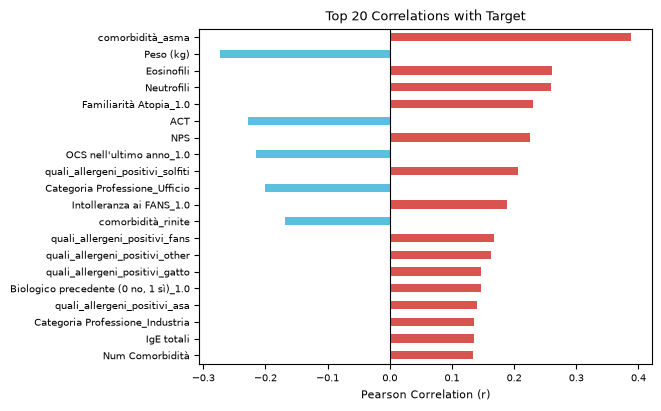

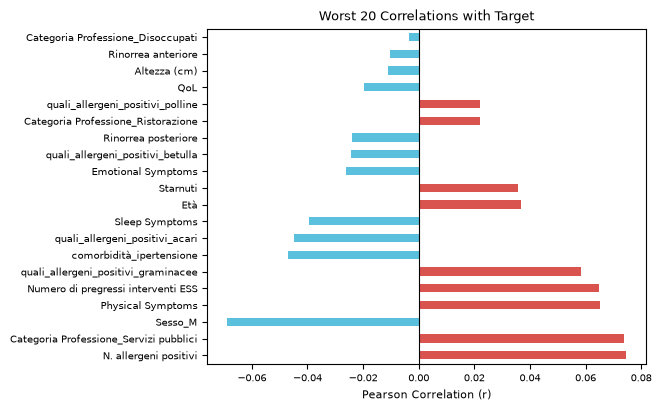

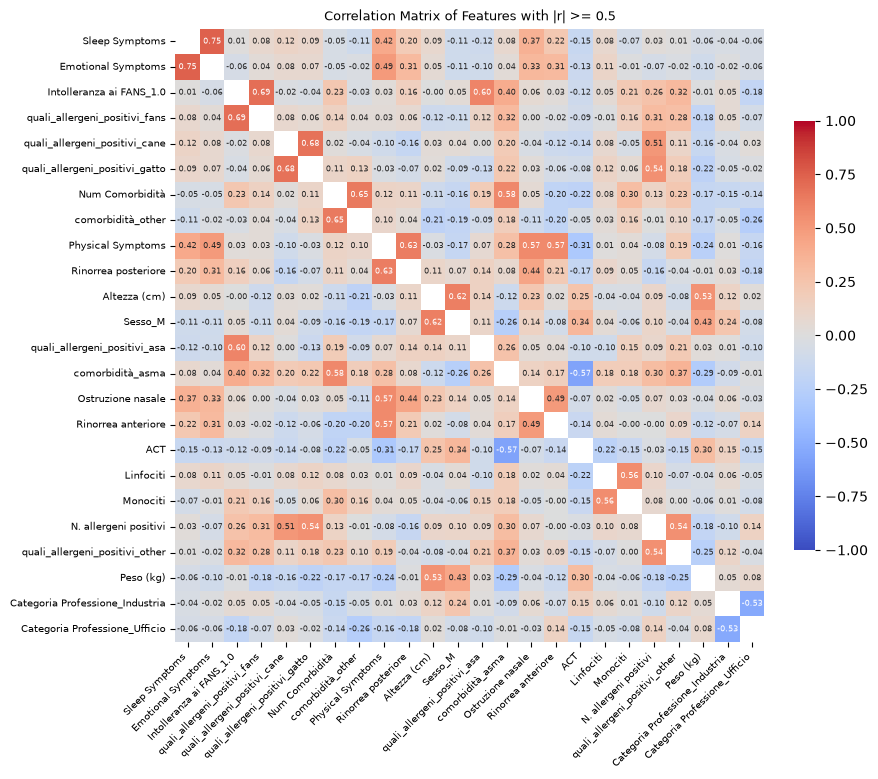

Test 41 successfully saved.


In [24]:
import gspread
import json
from pathlib import Path

# ============================================================
# GOOGLE SHEETS CONNECTION
# ============================================================

CREDENTIALS_PATH = "credentials.json"
SPREADSHEET_ID = "1pzs31DgAVyZuE2g-QWQKbgaH87kO_IBSnrM9HXrxrVQ"
WORKSHEET_NAME = "Foglio1"

gc = gspread.service_account(filename=CREDENTIALS_PATH)
sheet = gc.open_by_key(SPREADSHEET_ID).worksheet(WORKSHEET_NAME)

# ============================================================
# SERIALIZATION
# ============================================================

def to_json(obj):
    return json.dumps(obj, ensure_ascii=False, default=str)


# ============================================================
# EXCLUDED FEATURES
# ============================================================

active_features = {
    name: list(columns)
    for name, transformer, columns in ct.transformers
    if transformer != "drop"
}

excluded_features = {
    name: ", ".join(
        col for col in original_cols
        if col not in active_features.get(name, [])
    )
    for name, original_cols in all_features.items()
}

# ============================================================
# TRAIN SIZE
# ============================================================

train_size = len(X_train) / (len(X_train) + len(X_test))

# ============================================================
# PREPROCESSING
# ============================================================

transformers = {
    name: transformer
    for name, transformer, columns in ct.transformers
}


def get_step(group, step_type, attribute):
    transformer = transformers.get(group)
    if isinstance(transformer, Pipeline):
        transformer = next(
            (step for _, step in transformer.steps if isinstance(step, step_type)),
            None,
        )
    if not isinstance(transformer, step_type):
        return "None"
    return type(transformer).__name__ if attribute == "type" else getattr(transformer, attribute)


cont_imputer = get_step("num_cont", SimpleImputer, "strategy")
cont_scaler = get_step("num_cont", StandardScaler, "type")
discr_imputer = get_step("num_discr", SimpleImputer, "strategy")
discr_scaler = get_step("num_discr", StandardScaler, "type")
cat_imputer = get_step("cat", SimpleImputer, "strategy")
cat_encoder = get_step("cat", OneHotEncoder, "type")
multi_cat_imputer = "None"
multicat_encoder = (
    f"MultiLabelBinarizer(min_frequency={transformers['multi_cat'].min_frequency})"
    if isinstance(transformers.get("multi_cat"), MultiColumnBinarizer)
    else "None"
)
ord_imputer = get_step("ord", SimpleImputer, "strategy")
ord_scaler = get_step("ord", StandardScaler, "type")
augmentation_step = best_models["LinearSVC"].named_steps.get("smotenc")
augmentation = (
    to_json({"metodo": "SMOTENC", **augmentation_step.kw_args})
    if augmentation_step is not None else "None"
)

# ============================================================
# MODEL PARAMETERS AND RESULTS
# ============================================================

def get_model_info(model_name):
    model = best_models[model_name]
    y_pred = model.predict(X_test)
    test_results = {
        "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4),
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
    }
    return to_json(best_params[model_name]), to_json(test_results)


svc_params, svc_results = get_model_info("LinearSVC")
rbf_svc_params, rbf_svc_results = get_model_info("RBFSVC")
rf_params, rf_results = get_model_info("RandomForestClassifier")
lr_params, lr_results = get_model_info("LogisticRegression")
knn_params, knn_results = get_model_info("KNeighborsClassifier")
xgb_params, xgb_results = get_model_info("XGBClassifier")

# ============================================================
# TEST ID
# ============================================================

existing_ids = [
    int(value)
    for value in sheet.col_values(1)[1:]
    if value.strip().isdigit()
]

test_id = max(existing_ids, default=0) + 1

project_root = Path.cwd()
if project_root.name == "src" and project_root.parent.name == "Notebooks":
    project_root = project_root.parent.parent
output_dir = project_root / "output" / f"Test{test_id}"
output_dir.mkdir(parents=True, exist_ok=False)
analyze_feature_correlations(
    ct, X_train, y_train, top_n_target=20, corr_threshold=0.5,
    output_dir=output_dir,
)

# ============================================================
# APPEND ROW
# ============================================================

row = [
    test_id,
    excluded_features["num_cont"],
    excluded_features["num_discr"],
    excluded_features["cat"],
    excluded_features["multi_cat"],
    excluded_features["ord"],
    train_size,
    cont_imputer,
    cont_scaler,
    discr_imputer,
    discr_scaler,
    cat_imputer,
    cat_encoder,
    multi_cat_imputer,
    multicat_encoder,
    ord_imputer,
    ord_scaler,
    svc_params,
    svc_results,
    rf_params,
    rf_results,
    lr_params,
    lr_results,
    knn_params,
    knn_results,
    xgb_params,
    xgb_results,
    rbf_svc_params,
    rbf_svc_results,
    cv_folds["LinearSVC"],
    augmentation,
    RANDOM_STATE,
]

if sheet.cell(1, 24).value != "KNN params":
    sheet.update_cell(1, 24, "KNN params")
if sheet.cell(1, 25).value != "KNN results":
    sheet.update_cell(1, 25, "KNN results")
if sheet.cell(1, 26).value != "XGB params":
    sheet.update_cell(1, 26, "XGB params")
if sheet.cell(1, 27).value != "XGB results":
    sheet.update_cell(1, 27, "XGB results")
if sheet.cell(1, 28).value != "SVC RBF params":
    sheet.update_cell(1, 28, "SVC RBF params")
if sheet.cell(1, 29).value != "SVC RBF results":
    sheet.update_cell(1, 29, "SVC RBF results")
if sheet.cell(1, 30).value != "CV folds":
    sheet.update_cell(1, 30, "CV folds")
if sheet.cell(1, 31).value != "Augmentation":
    sheet.update_cell(1, 31, "Augmentation")
if sheet.cell(1, 32).value != "Seed":
    sheet.update_cell(1, 32, "Seed")

sheet.append_row(
    row,
    value_input_option="RAW",
    table_range="A1:AF1"
)

print(f"Test {test_id} successfully saved.")


In [25]:
# Beep al termine dell'esecuzione di tutte le celle
winsound.Beep(880, 500)


In [26]:
# # Linear SVC
# svc = Pipeline([
#     ('preprocessing', ct),
#     ('model', LinearSVC(
#         C=10,
#         loss='squared_hinge',
#         max_iter=3000,
#         random_state=RANDOM_STATE,
#         class_weight='balanced',
#         dual=True
#     ))
# ])

# svc.fit(X_train, y_train)

# y_pred_svc = svc.predict(X_test)

# f1_macro_svc = f1_score(y_test, y_pred_svc, average='macro')
# acc_svc = accuracy_score(y_test, y_pred_svc)
# precision_svc = precision_score(y_test, y_pred_svc)
# recall_svc = recall_score(y_test, y_pred_svc)

# print(confusion_matrix(y_test, y_pred_svc))
# print(classification_report(y_test, y_pred_svc))

# print(f"Macro F1 Score LinearSVC (Test set): {f1_macro_svc}")
# print(f"Accuracy LinearSVC (Test set): {acc_svc}")
# print(f"Precision LinearSVC (Test set): {precision_svc}")
# print(f"Recall LinearSVC (Test set): {recall_svc}")

In [27]:
# # Logistic Regression
# logr = Pipeline([
#     ('preprocessing', ct),
#     ('model', LogisticRegression(
#         C=5,
#         l1_ratio=1,
#         solver='saga',
#         max_iter=3000,
#         random_state=RANDOM_STATE,
#         class_weight='balanced'
#     ))
# ])

# logr.fit(X_train, y_train)

# y_pred_logr = logr.predict(X_test)

# f1_macro_logr = f1_score(y_test, y_pred_logr, average='macro')
# acc_logr = accuracy_score(y_test, y_pred_logr)
# precision_logr = precision_score(y_test, y_pred_logr)
# recall_logr = recall_score(y_test, y_pred_logr)

# print(f"Macro F1 Score LogisticRegression (Test set): {f1_macro_logr}")
# print(f"Accuracy LogisticRegression (Test set): {acc_logr}")
# print(f"Precision LogisticRegression (Test set): {precision_logr}")
# print(f"Recall LogisticRegression (Test set): {recall_logr}")

In [28]:
# # RandomForestClassifier
# rf = Pipeline([
#     ('preprocessing', ct),
#     ('model', RandomForestClassifier(
#         n_jobs=-1,
#         random_state=RANDOM_STATE,
#         max_depth=None,
#         min_samples_leaf=10,
#         n_estimators=500
#     ))
# ])

# rf.fit(X_train, y_train)

# y_pred_rf = rf.predict(X_test)

# f1_macro_rf = f1_score(y_test, y_pred_rf, average='macro')
# acc_rf = accuracy_score(y_test, y_pred_rf)
# precision_rf = precision_score(y_test, y_pred_rf)
# recall_rf = recall_score(y_test, y_pred_rf)

# print(f"Macro F1 Score RandomForestClassifier (Test set): {f1_macro_rf}")
# print(f"Accuracy RandomForestClassifier (Test set): {acc_rf}")
# print(f"Precision RandomForestClassifier (Test set): {precision_rf}")
# print(f"Recall RandomForestClassifier (Test set): {recall_rf}")

In [29]:
# import gspread

# # Connection parameters

# CREDENTIALS_PATH = "credentials.json"
# SPREADSHEET_ID = "1pzs31DgAVyZuE2g-QWQKbgaH87kO_IBSnrM9HXrxrVQ"
# WORKSHEET_NAME = "Foglio1"


# try:
#     # Authentication
#     gc = gspread.service_account(filename=CREDENTIALS_PATH)
#     print("[OK] Authentication successful")

#     # Spreadsheet access
#     spreadsheet = gc.open_by_key(SPREADSHEET_ID)
#     print(f"[OK] Spreadsheet found: {spreadsheet.title}")

#     # Worksheet access
#     sheet = spreadsheet.worksheet(WORKSHEET_NAME)
#     print(f"[OK] Worksheet found: {sheet.title}")

#     # Read headers
#     headers = sheet.row_values(1)

#     print("\nColumn headers:")
#     for i, header in enumerate(headers, start=1):
#         print(f"  {i}. {header}")

#     print("\n[SUCCESS] Connection established successfully.")

# except Exception as e:
#     print(f"\n[ERROR] {type(e).__name__}: {e}")